# Lab Mid Exam: HOG vs SIFT on Blood-Cell Images
**Google Colab | Q1-Q5 | 25 marks**

This notebook follows the attached brief. It is a runnable solution, not an already executed submission.
Enter your registration number and name in the first code cell, and read the prediction below **before running any code**.
Use a normal CPU runtime. Run cells in order. The dataset download requires internet access.

## Brief analysis and work plan
| Section | Required work | Marks | Approximate run/review time |
|---|---|---:|---|
| Q1 | BloodMNIST size 64; four classes; balanced subsets; shapes/counts; 16 example images | 3 | 10-15 minutes including download |
| Q2 | HOG length calculation and pictures; select C; validation metrics | 6 | 10-15 minutes |
| Q3 | Natural SIFT statistics; fixed-grid descriptors; select C; validation metrics | 7 | 15-20 minutes |
| Q4 | Prior prediction; frozen-model tests; table; three-sentence interpretation | 6 | 10-15 minutes |
| Q5 | Short answers; observed class confusions; honest AI log | 3 | 10 minutes |
| Submission | Review outputs, download executed notebook, export Markdown/PDF, upload to GitHub | — | 10-15 minutes |

Q2 and Q3 depend on Q1; Q4 depends on both fitted models; Q5 uses their recorded outputs.
No deadline or separate word limit is given; the brief states a 90-minute lab.

**Split-rule interpretation:** Q1 asks for all split counts, but Rule 3 says to touch the test set only in Q4.
This notebook loads train and validation in Q1 and prints the actual test counts in Q4, together with a complete split summary.
It never uses test performance to choose C.

## Q4(a): prediction written before execution
**Read and edit this text now if it does not match your own prediction.**

I predict that HOG will lose more accuracy under rotation because its orientation bins and cell positions are fixed, while SIFT pools gradients over local regions.
I predict that HOG will lose more accuracy under Gaussian noise because small noisy gradients may disturb its cell histograms more than SIFT's local aggregation.
These are hypotheses, not results: the fixed-grid SIFT implementation below uses a fixed angle and spatial order, so it is not fully rotation invariant.

If you change which model you predict, update `PREDICT_ROTATION_LOSER` and `PREDICT_NOISE_LOSER` in the first code cell to match.


In [1]:
# FIRST CODE CELL: enter your own details. Blank entries prompt you in Colab.
REGISTRATION_NUMBER = ""  # Example format: "064". Do not use the example as your own ID.
STUDENT_NAME = ""
PREDICT_ROTATION_LOSER = "HOG + SVM"  # Or "SIFT + SVM"
PREDICT_NOISE_LOSER = "HOG + SVM"     # Must match the prediction text above.

import re
if not REGISTRATION_NUMBER.strip():
    REGISTRATION_NUMBER = input("Enter your registration number: ").strip()
if not STUDENT_NAME.strip():
    STUDENT_NAME = input("Enter your name: ").strip()
digits = "".join(re.findall(r"[0-9]", REGISTRATION_NUMBER))
if len(digits) < 2 or not STUDENT_NAME:
    raise ValueError("Enter a registration number with at least two digits and your name.")
SEED = int(digits[-2:])
LAST_DIGIT = int(digits[-1])
HOG_CELL = 8 if LAST_DIGIT % 2 == 0 else 16
SIFT_GRID = 4 if LAST_DIGIT <= 4 else 6
assert PREDICT_ROTATION_LOSER in {"HOG + SVM", "SIFT + SVM"}
assert PREDICT_NOISE_LOSER in {"HOG + SVM", "SIFT + SVM"}
print("Student:", STUDENT_NAME, "| Registration:", REGISTRATION_NUMBER)
print("Seed:", SEED, "| HOG cell:", (HOG_CELL, HOG_CELL), "| SIFT grid:", (SIFT_GRID, SIFT_GRID))
print("Expected HOG length:", (128 // HOG_CELL - 1) ** 2 * 2 * 2 * 9)
print("Expected SIFT length:", SIFT_GRID ** 2 * 128)


Enter your registration number: 033
Enter your name: Fahad Bin Shafi
Student: Fahad Bin Shafi | Registration: 033
Seed: 33 | HOG cell: (16, 16) | SIFT grid: (4, 4)
Expected HOG length: 1764
Expected SIFT length: 2048


## Colab setup
Install the dataset and export tools. Reuse Colab's numerical libraries when present to avoid unnecessary upgrades.
If Colab requests a runtime restart after installation, restart and run from the first cell again.


In [2]:
import sys, subprocess, importlib.util
packages = ["medmnist>=3.0,<4", "nbformat", "nbconvert", "reportlab", "tabulate"]
for module, package in {
    "cv2": "opencv-python-headless", "skimage": "scikit-image",
    "sklearn": "scikit-learn", "pandas": "pandas",
    "matplotlib": "matplotlib", "tqdm": "tqdm"
}.items():
    if importlib.util.find_spec(module) is None:
        packages.append(package)
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])


0

In [3]:
import copy, json, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2, medmnist, skimage, sklearn
from medmnist import BloodMNIST, INFO
from skimage.feature import hog
from skimage.exposure import rescale_intensity
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.exceptions import ConvergenceWarning
from tqdm.auto import tqdm
from IPython.display import display, Markdown

pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)
np.random.seed(SEED)
cv2.setRNGSeed(SEED)
cv2.setNumThreads(1)
assert hasattr(cv2, "SIFT_create"), "An OpenCV build with SIFT is required."
CLASS_IDS = [1, 5, 6, 7]
CLASS_NAMES = ["eosinophil", "monocyte", "neutrophil", "platelet"]
NAME_BY_ID = dict(zip(CLASS_IDS, CLASS_NAMES))
for class_id, name in NAME_BY_ID.items():
    assert INFO["bloodmnist"]["label"][str(class_id)] == name
IMAGE_SIZE = 128
C_VALUES = [0.1, 1.0, 10.0]
DATA_DIR = Path("bloodmnist_data")
DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR = Path("labmid_results")
RESULTS_DIR.mkdir(exist_ok=True)
versions = {"Python": platform.python_version(), "NumPy": np.__version__,
            "OpenCV": cv2.__version__, "scikit-image": skimage.__version__,
            "scikit-learn": sklearn.__version__, "MedMNIST": medmnist.__version__}
display(pd.DataFrame(versions.items(), columns=["Package", "Version"]))
print("Training: 100/class; validation: 30/class; test: 30/class (loaded in Q4).")
print("Preprocessing: RGB to grayscale, resize 128 x 128, float32 in [0, 1].")


,Package,Version
0,Python,3.13.18
1,NumPy,2.1.3
2,OpenCV,5.0.0
3,scikit-image,0.25.2
4,scikit-learn,1.6.1
5,MedMNIST,3.0.2


Training: 100/class; validation: 30/class; test: 30/class (loaded in Q4).
Preprocessing: RGB to grayscale, resize 128 x 128, float32 in [0, 1].


# Q1. Data setup (3 marks)
Use the official training and validation splits separately. Choose each class without replacement, using a random generator derived from your seed and the split identifier.
No new train/test split is made. Test loading is deferred to Q4.


100%|██████████| 156M/156M [01:07<00:00, 2.32MB/s]


Train: RGB (400, 64, 64, 3); prepared (400, 128, 128); labels (400,)
Validation: RGB (120, 64, 64, 3); prepared (120, 128, 128); labels (120,)


,Split,Images,eosinophil,monocyte,neutrophil,platelet
0,Train,400,100,100,100,100
1,Validation,120,30,30,30,30


Test: not loaded yet; actual shapes and counts will appear in Q4.


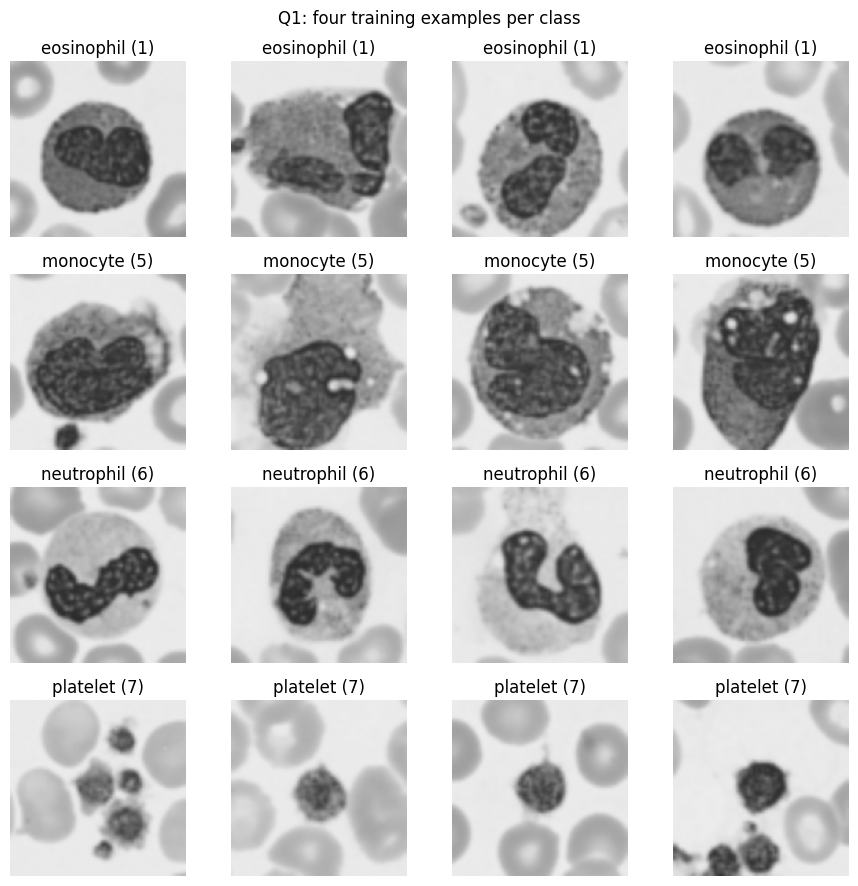

In [4]:
def load_subset(split, per_class):
    dataset = BloodMNIST(split=split, root=str(DATA_DIR), size=64, download=True)
    labels = dataset.labels.ravel().astype(int)
    split_number = {"train": 0, "val": 1, "test": 2}[split]
    rng = np.random.default_rng(np.random.SeedSequence([SEED, split_number]))
    indices = []
    for class_id in CLASS_IDS:
        available = np.flatnonzero(labels == class_id)
        if len(available) < per_class:
            raise ValueError(f"Not enough images in {split} for class {class_id}.")
        indices.extend(rng.choice(available, size=per_class, replace=False))
    indices = np.asarray(indices, dtype=int)
    rng.shuffle(indices)
    rgb = dataset.imgs[indices].copy()
    y = labels[indices].copy()
    assert rgb.shape == (4 * per_class, 64, 64, 3)
    assert len(np.unique(indices)) == len(indices)
    assert all(np.sum(y == c) == per_class for c in CLASS_IDS)
    return rgb, y, indices

def prepare_images(rgb_images):
    prepared = []
    for rgb in rgb_images:
        gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
        gray = cv2.resize(gray, (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_LINEAR)
        prepared.append(gray.astype(np.float32) / 255.0)
    result = np.stack(prepared)
    assert result.shape[1:] == (128, 128)
    assert np.isfinite(result).all() and result.min() >= 0 and result.max() <= 1
    return result

def split_summary(split, rgb, X, y):
    print(f"{split}: RGB {rgb.shape}; prepared {X.shape}; labels {y.shape}")
    return {"Split": split, "Images": len(y), **{NAME_BY_ID[c]: int(np.sum(y == c)) for c in CLASS_IDS}}

train_rgb, y_train, train_indices = load_subset("train", 100)
val_rgb, y_val, val_indices = load_subset("val", 30)
X_train = prepare_images(train_rgb)
X_val = prepare_images(val_rgb)
split_rows = [split_summary("Train", train_rgb, X_train, y_train),
              split_summary("Validation", val_rgb, X_val, y_val)]
display(pd.DataFrame(split_rows))
print("Test: not loaded yet; actual shapes and counts will appear in Q4.")

fig, axes = plt.subplots(4, 4, figsize=(9, 9))
for row, class_id in enumerate(CLASS_IDS):
    chosen = np.flatnonzero(y_train == class_id)[:4]
    for col, index in enumerate(chosen):
        axes[row, col].imshow(X_train[index], cmap="gray", vmin=0, vmax=1)
        axes[row, col].set_title(f"{NAME_BY_ID[class_id]} ({class_id})")
        axes[row, col].axis("off")
fig.suptitle("Q1: four training examples per class")
plt.tight_layout()
plt.show()


# Q2. HOG + SVM (6 marks)
## Feature length calculated by hand
For a 128 x 128 image with square cells of side **c**, there are **128/c** cells along each axis.
A 2 x 2 block moves by one cell, giving **(128/c - 1)** blocks along each axis.
Each block contributes **2 x 2 x 9 = 36** values.

**Feature length = (128/c - 1) x (128/c - 1) x 36.**

- If the last registration digit is even: c = 8, so **15 x 15 x 36 = 8,100**.
- If the last registration digit is odd: c = 16, so **7 x 7 x 36 = 1,764**.

The code prints and checks the applicable calculation. HOG uses L2-Hys block normalisation.


HOG:   0%|          | 0/400 [00:00<?, ?it/s]

HOG:   0%|          | 0/120 [00:00<?, ?it/s]

HOG training shape: (400, 1764) | validation shape: (120, 1764)
HOG length: (8 - 1)^2 x 36 = 1764


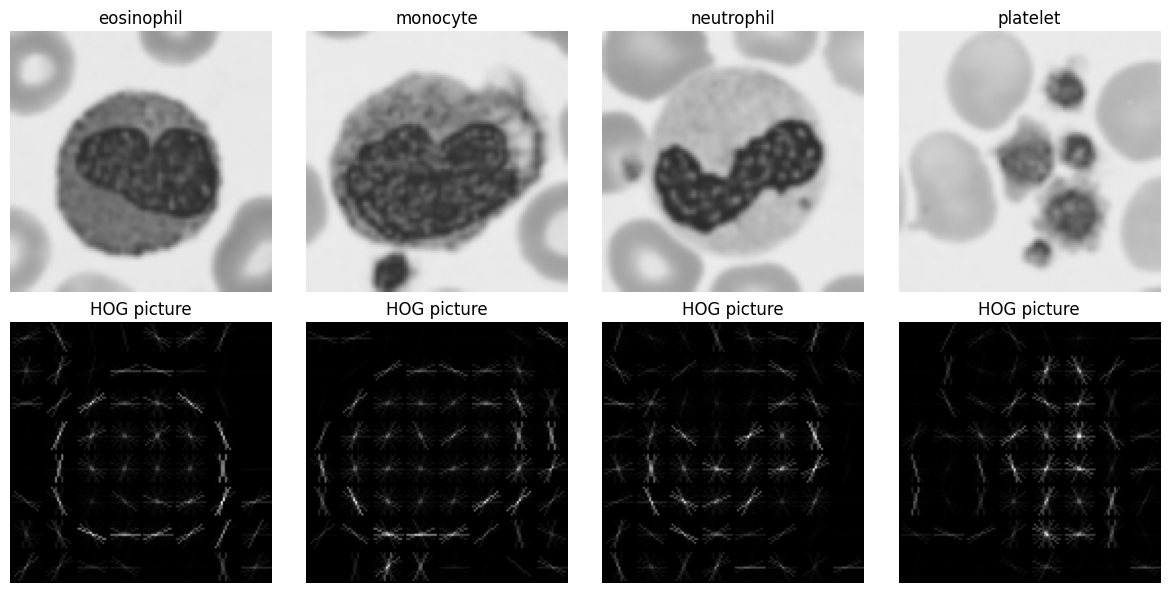

In [5]:
HOG_KWARGS = dict(orientations=9, pixels_per_cell=(HOG_CELL, HOG_CELL),
                  cells_per_block=(2, 2), block_norm="L2-Hys",
                  transform_sqrt=False, feature_vector=True, channel_axis=None)
def hog_features(images):
    return np.stack([hog(image, **HOG_KWARGS) for image in tqdm(images, desc="HOG")]).astype(np.float32)

H_train = hog_features(X_train)
H_val = hog_features(X_val)
expected_hog = (128 // HOG_CELL - 1) ** 2 * 36
assert H_train.shape == (400, expected_hog)
assert H_val.shape == (120, expected_hog)
print("HOG training shape:", H_train.shape, "| validation shape:", H_val.shape)
print(f"HOG length: ({128 // HOG_CELL} - 1)^2 x 36 = {expected_hog}")

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for col, class_id in enumerate(CLASS_IDS):
    index = np.flatnonzero(y_train == class_id)[0]
    _, picture = hog(X_train[index], visualize=True, **HOG_KWARGS)
    axes[0, col].imshow(X_train[index], cmap="gray", vmin=0, vmax=1)
    axes[0, col].set_title(NAME_BY_ID[class_id])
    axes[1, col].imshow(rescale_intensity(picture, in_range="image"), cmap="gray")
    axes[1, col].set_title("HOG picture")
    axes[0, col].axis("off")
    axes[1, col].axis("off")
plt.tight_layout()
plt.show()


## Validation-only selection of C
Both models use the same training-only StandardScaler followed by LinearSVC.
The scaler's means and standard deviations are fitted only on training features.
Choose the highest validation accuracy; break ties by higher macro-F1, then smaller C.
This rule is fixed before any test evaluation. The winning training-fitted pipeline is retained without refitting on validation.


,C,Validation accuracy,Validation macro-F1
0,0.1,0.8,0.79734
1,1.0,0.8,0.79734
2,10.0,0.8,0.79734


HOG + SVM selected C: 0.1
Validation accuracy: 0.8000
Validation macro-F1: 0.7973


,Pred eosinophil,Pred monocyte,Pred neutrophil,Pred platelet
True eosinophil,20,5,3,2
True monocyte,3,25,2,0
True neutrophil,6,3,21,0
True platelet,0,0,0,30


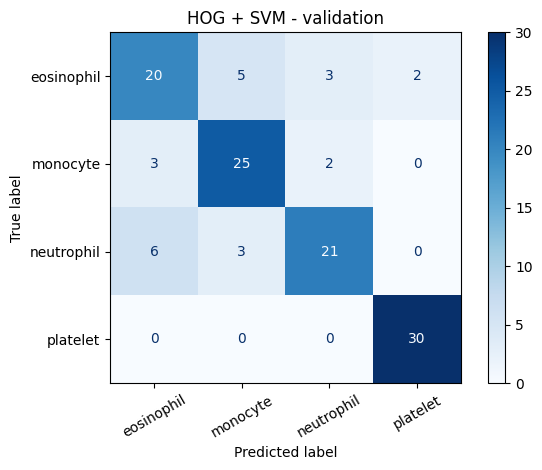

In [6]:
def tune_svm(train_features, val_features, model_name):
    rows, fitted = [], {}
    for C in C_VALUES:
        pipeline = make_pipeline(StandardScaler(), LinearSVC(
            C=C, dual=True, random_state=SEED, max_iter=100000, tol=1e-4))
        # Stop rather than silently report an unconverged result.
        with warnings.catch_warnings():
            warnings.simplefilter("error", ConvergenceWarning)
            pipeline.fit(train_features, y_train)
        prediction = pipeline.predict(val_features)
        rows.append({"C": C, "Validation accuracy": accuracy_score(y_val, prediction),
                     "Validation macro-F1": f1_score(y_val, prediction, labels=CLASS_IDS,
                                                     average="macro", zero_division=0)})
        fitted[C] = pipeline
    scores = pd.DataFrame(rows)
    ranked = scores.sort_values(["Validation accuracy", "Validation macro-F1", "C"],
                                ascending=[False, False, True])
    best_C = float(ranked.iloc[0]["C"])
    best_model = fitted[best_C]
    prediction = best_model.predict(val_features)
    matrix = confusion_matrix(y_val, prediction, labels=CLASS_IDS)
    display(scores)
    print(model_name, "selected C:", best_C)
    print(f"Validation accuracy: {accuracy_score(y_val, prediction):.4f}")
    print(f"Validation macro-F1: {f1_score(y_val, prediction, labels=CLASS_IDS, average='macro', zero_division=0):.4f}")
    display(pd.DataFrame(matrix, index=["True " + n for n in CLASS_NAMES], columns=["Pred " + n for n in CLASS_NAMES]))
    ConfusionMatrixDisplay(matrix, display_labels=CLASS_NAMES).plot(cmap="Blues", xticks_rotation=30)
    plt.title(model_name + " - validation")
    plt.tight_layout()
    plt.show()
    return best_model, scores, matrix

hog_model, hog_scores, hog_val_cm = tune_svm(H_train, H_val, "HOG + SVM")


# Q3. SIFT + SVM (7 marks)
## Normal SIFT detection
Run `detectAndCompute` on all 400 selected training images.
Report the number of keypoints per image, including images with none.


Normal SIFT detection:   0%|          | 0/400 [00:00<?, ?it/s]

,Images,Average keypoints,Minimum keypoints,Maximum keypoints,Images with zero keypoints
0,400,71.3925,8,188,0


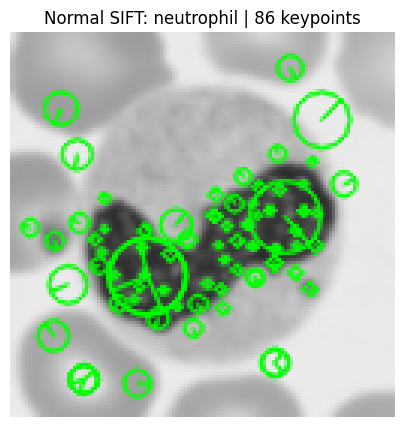

An SVM requires the same number of features for every image, but joining normal SIFT descriptors gives different lengths when keypoint counts vary.


In [7]:
sift = cv2.SIFT_create()
def to_uint8(image):
    # OpenCV SIFT requires grayscale uint8 input.
    return np.rint(np.clip(image, 0, 1) * 255).astype(np.uint8)

keypoint_counts = []
example_keypoints = None
example_index = 0
for index, image in enumerate(tqdm(X_train, desc="Normal SIFT detection")):
    keypoints, descriptors = sift.detectAndCompute(to_uint8(image), None)
    keypoint_counts.append(len(keypoints))
    if len(keypoints) and example_keypoints is None:
        example_index, example_keypoints = index, keypoints
keypoint_counts = np.asarray(keypoint_counts)
keypoint_summary = pd.DataFrame([{
    "Images": len(keypoint_counts), "Average keypoints": float(keypoint_counts.mean()),
    "Minimum keypoints": int(keypoint_counts.min()), "Maximum keypoints": int(keypoint_counts.max()),
    "Images with zero keypoints": int(np.sum(keypoint_counts == 0))
}])
display(keypoint_summary)
if example_keypoints is None:
    example_keypoints = []
picture = cv2.drawKeypoints(to_uint8(X_train[example_index]), example_keypoints, None,
                           color=(0, 255, 0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5))
plt.imshow(cv2.cvtColor(picture, cv2.COLOR_BGR2RGB))
plt.title(f"Normal SIFT: {NAME_BY_ID[int(y_train[example_index])]} | {len(example_keypoints)} keypoints")
plt.axis("off")
plt.show()
print("An SVM requires the same number of features for every image, but joining normal SIFT descriptors gives different lengths when keypoint counts vary.")


**Why variable counts cause a problem:** An SVM requires the same number of features for every image, but joining normal SIFT descriptors gives different lengths when keypoint counts vary.

## Fixed grid and feature length calculated by hand
Each SIFT keypoint gives **128 values**.

- Last registration digit 0-4: **4 x 4 = 16 keypoints; 16 x 128 = 2,048 features**.
- Last registration digit 5-9: **6 x 6 = 36 keypoints; 36 x 128 = 4,608 features**.

Use a regular grid with coordinates evenly spaced from 16 to 112 pixels on both axes and **keypoint size 32**.
Concatenate descriptors from left to right and then top to bottom.
The brief does not specify keypoint angle; here every grid point has **angle 0 degrees**, fixed before testing.
`compute` uses these supplied points, so this is a fixed-angle dense SIFT descriptor, not full detected-and-orientation-aligned SIFT.


Fixed-grid SIFT:   0%|          | 0/400 [00:00<?, ?it/s]

Fixed-grid SIFT:   0%|          | 0/120 [00:00<?, ?it/s]

SIFT training shape: (400, 2048) | validation shape: (120, 2048)
SIFT length: 4 x 4 x 128 = 2048
Fixed keypoint size: 32; fixed angle: 0 degrees; row-major descriptor order.


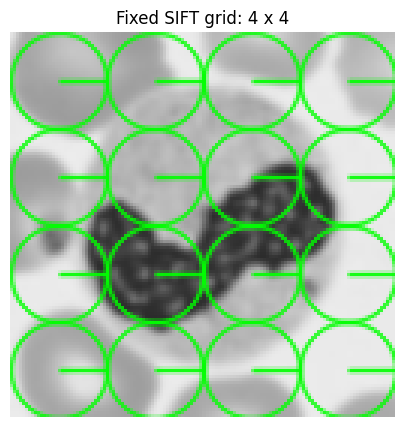

,C,Validation accuracy,Validation macro-F1
0,0.1,0.75,0.747563
1,1.0,0.75,0.747563
2,10.0,0.75,0.747563


SIFT + SVM selected C: 0.1
Validation accuracy: 0.7500
Validation macro-F1: 0.7476


,Pred eosinophil,Pred monocyte,Pred neutrophil,Pred platelet
True eosinophil,16,9,3,2
True monocyte,4,24,2,0
True neutrophil,10,0,20,0
True platelet,0,0,0,30


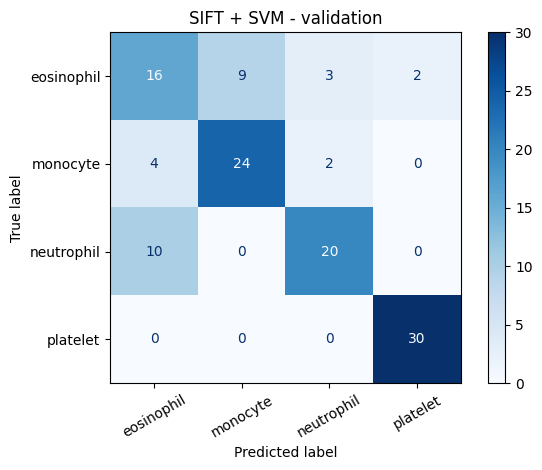

In [8]:
def grid_keypoints():
    coordinates = np.linspace(16, IMAGE_SIZE - 16, SIFT_GRID)
    return [cv2.KeyPoint(float(x), float(y), 32.0, 0.0)
            for y in coordinates for x in coordinates]

def sift_grid_features(images):
    vectors = []
    for image in tqdm(images, desc="Fixed-grid SIFT"):
        supplied = grid_keypoints()
        returned, descriptors = sift.compute(to_uint8(image), supplied)
        expected_shape = (SIFT_GRID ** 2, 128)
        if descriptors is None or descriptors.shape != expected_shape:
            raise RuntimeError(f"Expected {expected_shape} SIFT descriptors at the fixed points.")
        assert np.allclose([k.pt for k in returned], [k.pt for k in supplied])
        vectors.append(descriptors.ravel())
    result = np.stack(vectors).astype(np.float32)
    assert np.isfinite(result).all()
    return result

S_train = sift_grid_features(X_train)
S_val = sift_grid_features(X_val)
expected_sift = SIFT_GRID ** 2 * 128
assert S_train.shape == (400, expected_sift)
assert S_val.shape == (120, expected_sift)
print("SIFT training shape:", S_train.shape, "| validation shape:", S_val.shape)
print(f"SIFT length: {SIFT_GRID} x {SIFT_GRID} x 128 = {expected_sift}")
print("Fixed keypoint size: 32; fixed angle: 0 degrees; row-major descriptor order.")
picture = cv2.drawKeypoints(to_uint8(X_train[0]), grid_keypoints(), None,
                           color=(0, 255, 0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5))
plt.imshow(cv2.cvtColor(picture, cv2.COLOR_BGR2RGB))
plt.title(f"Fixed SIFT grid: {SIFT_GRID} x {SIFT_GRID}")
plt.axis("off")
plt.show()

sift_model, sift_scores, sift_val_cm = tune_svm(S_train, S_val, "SIFT + SVM")


# Q4. Robustness (6 marks)
The prediction is in the text cell at the top, before all execution.
Freeze both selected pipelines, including their scalers. Load the official test split now.
Use exactly the same selected test images for both models and all three conditions.

- **Clean:** prepared grayscale images in [0, 1].
- **Rotated:** 20 degrees counterclockwise about the image centre, bilinear interpolation, reflection padding, original 128 x 128 canvas.
- **Noisy:** independent additive zero-mean Gaussian noise with sigma 0.05, then clip to [0, 1]. A separate deterministic random generator is used.

Rotation and noise are separate conditions, applied to the clean images before feature extraction. SIFT converts each condition to uint8 after corruption, as required by OpenCV.


Test: RGB (120, 64, 64, 3); prepared (120, 128, 128); labels (120,)


,Split,Images,eosinophil,monocyte,neutrophil,platelet
0,Train,400,100,100,100,100
1,Validation,120,30,30,30,30
2,Test,120,30,30,30,30


Rotation: 20 degrees counterclockwise; Gaussian noise sigma: 0.05.
Generated noise standard deviation before clipping: 0.05001
After clipping, the noise distribution at pixels near 0 or 1 is truncated.


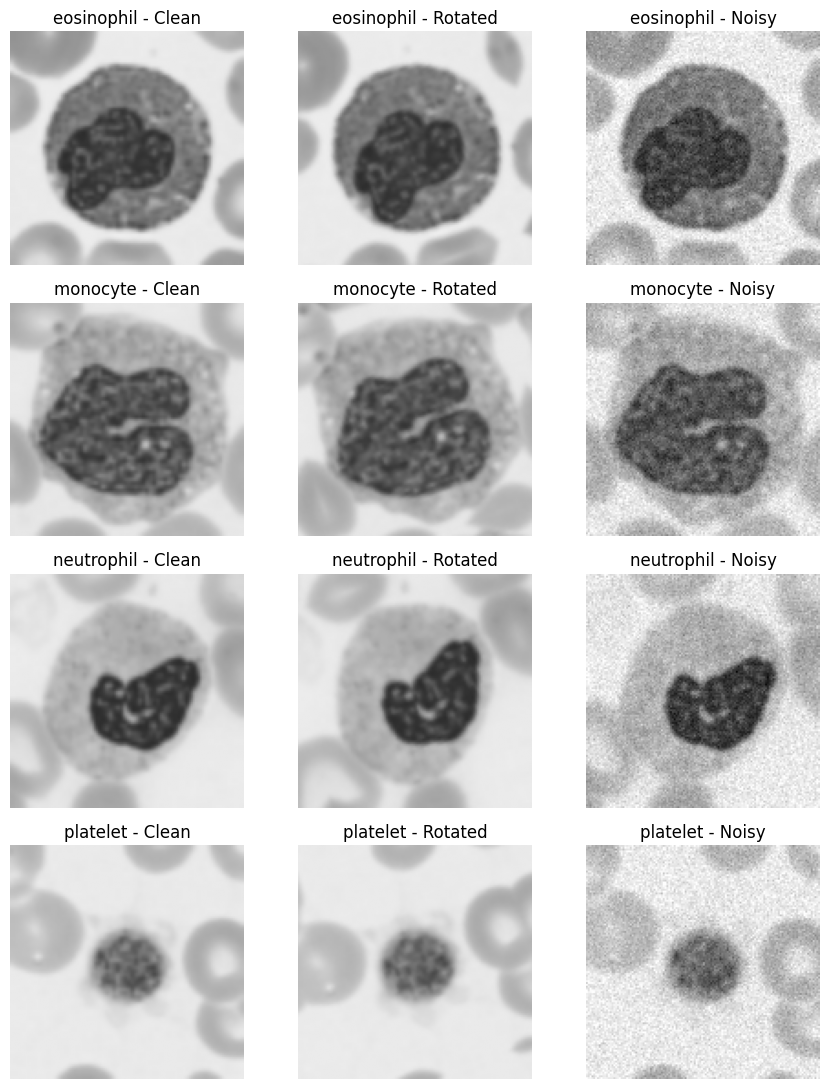

HOG:   0%|          | 0/120 [00:00<?, ?it/s]

HOG:   0%|          | 0/120 [00:00<?, ?it/s]

HOG:   0%|          | 0/120 [00:00<?, ?it/s]

Fixed-grid SIFT:   0%|          | 0/120 [00:00<?, ?it/s]

Fixed-grid SIFT:   0%|          | 0/120 [00:00<?, ?it/s]

Fixed-grid SIFT:   0%|          | 0/120 [00:00<?, ?it/s]

Required table: accuracies as proportions (0 to 1).


,Clean accuracy,Rotated accuracy,Noisy accuracy
Model,,,
HOG + SVM,0.6500,0.7417,0.2500
SIFT + SVM,0.7917,0.7417,0.7833


,Rotation loss (percentage points),Noise loss (percentage points)
Model,,
HOG + SVM,-9.17,40.00
SIFT + SVM,5.00,0.83


Negative loss means accuracy improved. Frozen scaler/model checks passed.


In [9]:
frozen_hog = copy.deepcopy(hog_model)
frozen_sift = copy.deepcopy(sift_model)
def model_state(model):
    scaler = model.named_steps["standardscaler"]
    svm = model.named_steps["linearsvc"]
    return [scaler.mean_.copy(), scaler.scale_.copy(), svm.coef_.copy(), svm.intercept_.copy()]
states_before = {"HOG + SVM": model_state(frozen_hog), "SIFT + SVM": model_state(frozen_sift)}

test_rgb, y_test, test_indices = load_subset("test", 30)
X_test = prepare_images(test_rgb)
test_row = split_summary("Test", test_rgb, X_test, y_test)
all_split_counts = pd.DataFrame(split_rows + [test_row])
display(all_split_counts)

rotation_matrix = cv2.getRotationMatrix2D(((IMAGE_SIZE - 1) / 2, (IMAGE_SIZE - 1) / 2), 20, 1.0)
X_rotated = np.stack([cv2.warpAffine(image, rotation_matrix, (IMAGE_SIZE, IMAGE_SIZE),
                      flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
                      for image in X_test]).astype(np.float32)
noise_rng = np.random.default_rng(np.random.SeedSequence([SEED, 3]))
noise = noise_rng.normal(0.0, 0.05, X_test.shape).astype(np.float32)
X_noisy = np.clip(X_test + noise, 0, 1).astype(np.float32)
conditions = {"Clean": X_test, "Rotated": X_rotated, "Noisy": X_noisy}
print("Rotation: 20 degrees counterclockwise; Gaussian noise sigma: 0.05.")
print(f"Generated noise standard deviation before clipping: {noise.std():.5f}")
print("After clipping, the noise distribution at pixels near 0 or 1 is truncated.")
for condition, images in conditions.items():
    assert images.shape == (120, 128, 128)
    assert np.isfinite(images).all() and 0 <= images.min() <= images.max() <= 1

fig, axes = plt.subplots(4, 3, figsize=(9, 11))
for row, class_id in enumerate(CLASS_IDS):
    index = np.flatnonzero(y_test == class_id)[0]
    for col, (condition, images) in enumerate(conditions.items()):
        axes[row, col].imshow(images[index], cmap="gray", vmin=0, vmax=1)
        axes[row, col].set_title(f"{NAME_BY_ID[class_id]} - {condition}")
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

records, test_predictions, test_cms = [], {}, {}
for model_name, model, extractor in [
    ("HOG + SVM", frozen_hog, hog_features),
    ("SIFT + SVM", frozen_sift, sift_grid_features)
]:
    for condition, images in conditions.items():
        features = extractor(images)
        predictions = model.predict(features)  # No fit call anywhere in Q4.
        test_predictions[(model_name, condition)] = predictions
        test_cms[(model_name, condition)] = confusion_matrix(y_test, predictions, labels=CLASS_IDS)
        records.append({"Model": model_name, "Condition": condition,
                        "Accuracy": accuracy_score(y_test, predictions)})
    for old, new in zip(states_before[model_name], model_state(model)):
        assert np.array_equal(old, new), "A frozen model changed during evaluation."

robustness = pd.DataFrame(records).pivot(index="Model", columns="Condition", values="Accuracy")
robustness = robustness.reindex(index=["HOG + SVM", "SIFT + SVM"], columns=["Clean", "Rotated", "Noisy"])
robustness.columns.name = None
print("Required table: accuracies as proportions (0 to 1).")
display(robustness.rename(columns={c: c + " accuracy" for c in robustness.columns}).round(4))
accuracy_drops = pd.DataFrame({
    "Rotation loss (percentage points)": 100 * (robustness["Clean"] - robustness["Rotated"]),
    "Noise loss (percentage points)": 100 * (robustness["Clean"] - robustness["Noisy"])
})
display(accuracy_drops.round(2))
print("Negative loss means accuracy improved. Frozen scaler/model checks passed.")


## Q4(c). Three-sentence interpretation from your table
The next cell creates a draft using the measured values and the predictions recorded in the first cell.
Read it and check it against your table. Keep it as output, or copy it into a text cell in your own words.
Do not change the original prediction after seeing the results.


In [10]:
def prediction_sentence(condition, predicted):
    drops = robustness["Clean"] - robustness[condition]
    h, s = float(drops["HOG + SVM"]), float(drops["SIFT + SVM"])
    if np.isclose(h, s):
        verdict = f"the prediction that {predicted} would lose more was not supported because the losses were equal"
    else:
        actual = "HOG + SVM" if h > s else "SIFT + SVM"
        verdict = f"the prediction that {predicted} would lose more was {'correct' if actual == predicted else 'incorrect'}"
    return f"Under {condition.lower()}, HOG lost {100*h:.2f} percentage points and SIFT lost {100*s:.2f} percentage points, so {verdict}."

q4_answer = " ".join([
    prediction_sentence("Rotated", PREDICT_ROTATION_LOSER),
    prediction_sentence("Noisy", PREDICT_NOISE_LOSER),
    f"The clean accuracies were {robustness.loc['HOG + SVM', 'Clean']:.2%} for HOG and {robustness.loc['SIFT + SVM', 'Clean']:.2%} for SIFT, and these results describe this fixed-grid implementation on the {len(y_test)} selected test images."
])
display(Markdown(q4_answer))


Under rotated, HOG lost -9.17 percentage points and SIFT lost 5.00 percentage points, so the prediction that HOG + SVM would lose more was incorrect. Under noisy, HOG lost 40.00 percentage points and SIFT lost 0.83 percentage points, so the prediction that HOG + SVM would lose more was correct. The clean accuracies were 65.00% for HOG and 79.17% for SIFT, and these results describe this fixed-grid implementation on the 120 selected test images.

# Q5. Short answers and AI log (3 marks)
## (a) Why does HOG use block normalisation?
HOG normalises neighbouring cells together to reduce the effect of changes in lighting and contrast on gradient strength.
This helps the descriptor represent the relative pattern of edges rather than mainly their brightness.

## (b) Why is it wrong to choose C using the test set?
Choosing C using test results would let the test data influence model selection, making the reported test accuracy too optimistic as an independent performance estimate.
Use validation data to choose C and keep the test set for the final comparison of the frozen models.

The next cell checks the training-only scaler and uses a darker training image to demonstrate the normalisation behaviour; no extra test experiment is performed.


In [11]:
for model_name, model, features in [
    ("HOG + SVM", frozen_hog, H_train), ("SIFT + SVM", frozen_sift, S_train)
]:
    scaler = model.named_steps["standardscaler"]
    assert int(scaler.n_samples_seen_) == len(y_train)
    assert np.allclose(scaler.mean_, features.mean(axis=0, dtype=np.float64))
    print(model_name, "scaler fitted on", scaler.n_samples_seen_, "training rows only;",
          "selected C =", model.named_steps["linearsvc"].C)

original_hog = hog(X_train[0], **HOG_KWARGS)
darker_hog = hog(X_train[0] * 0.6, **HOG_KWARGS)
relative_change = np.linalg.norm(original_hog - darker_hog) / max(np.linalg.norm(original_hog), 1e-12)
print(f"Normalised HOG relative change after multiplying a training image by 0.6: {relative_change:.6f}")
print("This checks one brightness change; it does not prove invariance to all lighting changes.")


HOG + SVM scaler fitted on 400 training rows only; selected C = 0.1
SIFT + SVM scaler fitted on 400 training rows only; selected C = 0.1
Normalised HOG relative change after multiplying a training image by 0.6: 0.000000
This checks one brightness change; it does not prove invariance to all lighting changes.


## (c) Which two classes were most confused?
Use the **clean test confusion matrices already computed in Q4**, with both directions of confusion added for each unordered pair.
Report each model separately and a combined total across the two models. The combined total counts prediction errors, so an image misclassified by both models can contribute twice.
If several pairs tie, list all of them; if there are no errors, say so.


,Class pair,Errors in both directions
0,eosinophil / monocyte,21
1,eosinophil / neutrophil,16
3,monocyte / neutrophil,4
2,eosinophil / platelet,1
4,monocyte / platelet,0
5,neutrophil / platelet,0


,Class pair,Errors in both directions
0,eosinophil / monocyte,13
1,eosinophil / neutrophil,8
3,monocyte / neutrophil,2
4,monocyte / platelet,1
5,neutrophil / platelet,1
2,eosinophil / platelet,0


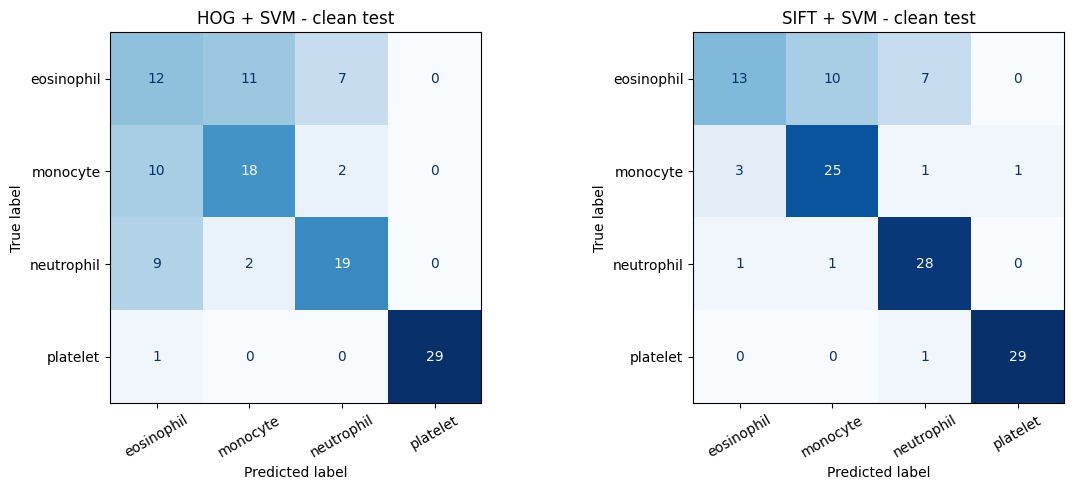

,Class pair,Errors in both directions
0,eosinophil / monocyte,34
1,eosinophil / neutrophil,24
3,monocyte / neutrophil,6
2,eosinophil / platelet,1
4,monocyte / platelet,1
5,neutrophil / platelet,1


HOG + SVM: the most-confused pair(s) were eosinophil and monocyte, with 21 errors in both directions per pair.
SIFT + SVM: the most-confused pair(s) were eosinophil and monocyte, with 13 errors in both directions per pair.
Both models combined: the most-confused pair(s) were eosinophil and monocyte, with 34 errors in both directions per pair.


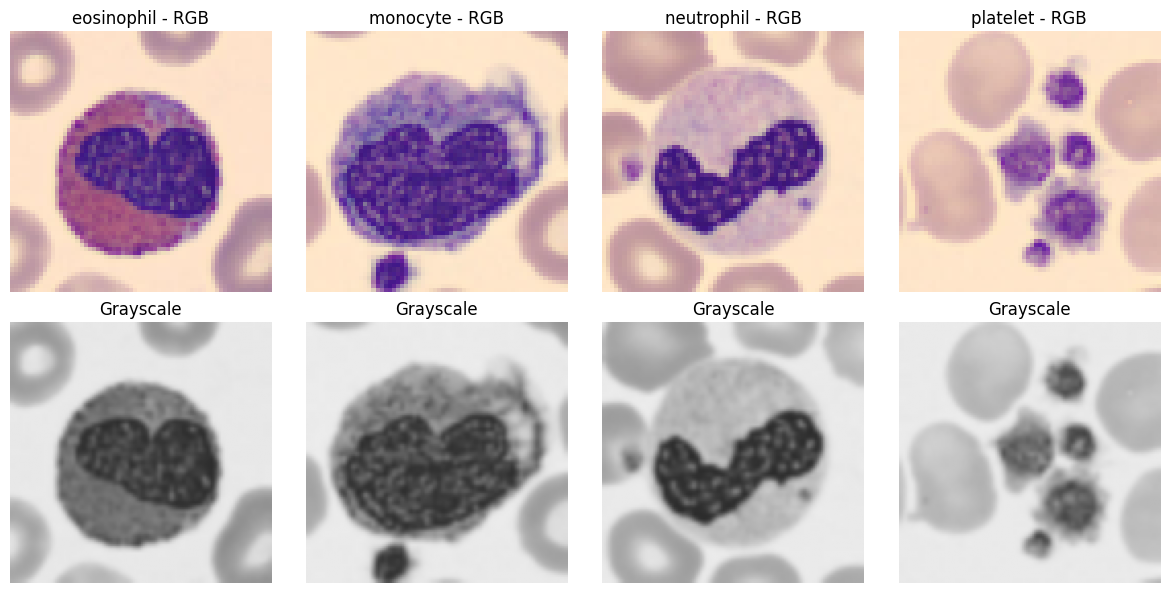

The RGB-to-grayscale examples show that colour information is removed, which may make cells with similar shapes and different staining colours harder to separate. This is a possible explanation, not a tested cause of the observed errors, because no RGB classifier was compared.


In [12]:
def pair_counts(matrix):
    return {(CLASS_NAMES[i], CLASS_NAMES[j]): int(matrix[i, j] + matrix[j, i])
            for i in range(4) for j in range(i + 1, 4)}

def describe_confusions(matrix, label):
    counts = pair_counts(matrix)
    top = max(counts.values())
    display(pd.DataFrame([{"Class pair": a + " / " + b, "Errors in both directions": n}
                          for (a, b), n in counts.items()]).sort_values("Errors in both directions", ascending=False))
    if top == 0:
        return f"{label} made no clean-test classification errors, so no most-confused pair can be identified."
    winners = [a + " and " + b for (a, b), n in counts.items() if n == top]
    return f"{label}: the most-confused pair(s) were {'; '.join(winners)}, with {top} errors in both directions per pair."

confusion_answers = []
combined_cm = np.zeros((4, 4), dtype=int)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, model_name in zip(axes, ["HOG + SVM", "SIFT + SVM"]):
    matrix = test_cms[(model_name, "Clean")]
    combined_cm += matrix
    ConfusionMatrixDisplay(matrix, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", xticks_rotation=30, colorbar=False)
    ax.set_title(model_name + " - clean test")
    confusion_answers.append(describe_confusions(matrix, model_name))
plt.tight_layout()
plt.show()
confusion_answers.append(describe_confusions(combined_cm, "Both models combined"))
for sentence in confusion_answers:
    print(sentence)

# Visual evidence from TRAINING images: no further test loading or fitting.
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for col, class_id in enumerate(CLASS_IDS):
    index = np.flatnonzero(y_train == class_id)[0]
    axes[0, col].imshow(train_rgb[index])
    axes[0, col].set_title(NAME_BY_ID[class_id] + " - RGB")
    axes[1, col].imshow(X_train[index], cmap="gray", vmin=0, vmax=1)
    axes[1, col].set_title("Grayscale")
    for row in range(2):
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()
grayscale_answer = (
    "The RGB-to-grayscale examples show that colour information is removed, which may make cells with similar shapes and different staining colours harder to separate. "
    "This is a possible explanation, not a tested cause of the observed errors, because no RGB classifier was compared."
)
print(grayscale_answer)


## (d) AI log
The brief permits AI but requires checking the result and being able to explain the code.
The table below is an honest starter log. **Edit the two student fields after checking your own run**; do not claim checks you have not performed.
Record any later AI prompts as additional rows.


In [13]:
# EDIT after reviewing the outputs. These fields deliberately do not invent your actions.
MY_CHANGES = "TO COMPLETE: list what you personally changed; write 'none beyond my details' if accurate."
MY_CHECKS = "TO COMPLETE: name the outputs you personally checked and what they showed."
ai_log = pd.DataFrame([{
    "Prompt (one line)": "Analyse the attached HOG vs SIFT brief and provide all code for Google Colab.",
    "What I changed": MY_CHANGES,
    "How I checked correctness": MY_CHECKS
}])
display(ai_log)
print("Checks available to review: subset counts, 16-image grid, HOG/SIFT lengths, keypoint plots,")
print("validation C tables, confusion matrices, corruption pictures and unchanged model/scaler arrays.")


,Prompt (one line),What I changed,How I checked correctness
0,Analyse the attached HOG vs SIFT brief and provide all code for Google Colab.,TO COMPLETE: list what you personally changed; write 'none beyond my details' if accurate.,TO COMPLETE: name the outputs you personally checked and what they showed.


Checks available to review: subset counts, 16-image grid, HOG/SIFT lengths, keypoint plots,
validation C tables, confusion matrices, corruption pictures and unchanged model/scaler arrays.


## Save reproducibility records
Save subset indices, parameters, versions, validation scores, test predictions and the output tables.
These files support checking your work; the executed notebook, Markdown and PDF are the required submission formats.


In [14]:
all_split_counts.to_csv(RESULTS_DIR / "split_counts.csv", index=False)
hog_scores.to_csv(RESULTS_DIR / "hog_validation.csv", index=False)
sift_scores.to_csv(RESULTS_DIR / "sift_validation.csv", index=False)
keypoint_summary.to_csv(RESULTS_DIR / "sift_keypoint_statistics.csv", index=False)
robustness.to_csv(RESULTS_DIR / "robustness_accuracy.csv")
accuracy_drops.to_csv(RESULTS_DIR / "accuracy_drops.csv")
ai_log.to_csv(RESULTS_DIR / "ai_log.csv", index=False)
np.savez(RESULTS_DIR / "selected_indices.npz", train=train_indices, validation=val_indices, test=test_indices)
predictions_table = pd.DataFrame({"Test source index": test_indices, "True label": y_test})
for (model_name, condition), prediction in test_predictions.items():
    predictions_table[model_name + " - " + condition] = prediction
predictions_table.to_csv(RESULTS_DIR / "test_predictions.csv", index=False)
settings = {"registration": REGISTRATION_NUMBER, "name": STUDENT_NAME, "seed": SEED,
            "hog_cell": HOG_CELL, "sift_grid": SIFT_GRID, "sift_keypoint_size": 32,
            "sift_angle": 0, "rotation_degrees": 20, "noise_sigma": 0.05,
            "hog_C": frozen_hog.named_steps["linearsvc"].C,
            "sift_C": frozen_sift.named_steps["linearsvc"].C, "versions": versions}
(RESULTS_DIR / "settings.json").write_text(json.dumps(settings, indent=2))
(RESULTS_DIR / "generated_answers.txt").write_text(q4_answer + "\n\n" + "\n".join(confusion_answers) + "\n\n" + grayscale_answer)
print("Saved results to", RESULTS_DIR.resolve())
print("Next: review your answers, complete the AI log, and export the executed notebook.")


Saved results to /content/labmid_results
Next: review your answers, complete the AI log, and export the executed notebook.


## Submission: executed notebook, Markdown for GitHub, and PDF
1. Check all Q1-Q5 outputs and complete your AI log. Read the three-sentence Q4 answer.
2. Rename the notebook in Colab to **RollNo_Name_LabMid.ipynb**, replacing RollNo and Name with your details.
3. Choose **File > Download > Download .ipynb** to download the notebook with its outputs. Do this **before** the export step below.
4. Set `RUN_EXPORT = True` below and run that cell. Upload the executed `.ipynb` you just downloaded when prompted.
5. The exporter checks for unexecuted/error cells, creates Markdown with image files, a PDF copy containing code and outputs, and an HTML copy. It downloads a ZIP.
6. Extract the ZIP and upload the `.ipynb`, `.md`, generated image folders and PDF to your GitHub repository. Keep relative image paths unchanged so figures appear in the Markdown.
7. Open the Markdown on GitHub and open the PDF to check that tables and figures are visible.

The export cell is deliberately skipped by a normal **Run all**; it needs the already executed notebook as input. Exporting does not rerun the models.
The PDF is a plain, readable copy of notebook text, code and outputs; HTML preserves richer notebook styling.


In [15]:
RUN_EXPORT = False  # Run all skips export. Change to True after downloading the executed notebook.
if RUN_EXPORT:
    import base64, io, shutil, textwrap, html
    import nbformat
    from nbconvert import MarkdownExporter, HTMLExporter
    from google.colab import files
    from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Image as PDFImage, Preformatted
    from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
    from reportlab.lib import colors
    from reportlab.lib.enums import TA_LEFT
    from reportlab.lib.utils import ImageReader

    print("Upload your executed notebook (.ipynb), downloaded with outputs after Q1-Q5.")
    uploaded = files.upload()
    notebook_names = [name for name in uploaded if name.lower().endswith(".ipynb")]
    if len(notebook_names) != 1:
        raise ValueError("Upload exactly one executed .ipynb file.")
    executed = nbformat.reads(uploaded[notebook_names[0]].decode("utf-8"), as_version=4)
    # Remove only this optional export cell to avoid recursive export code/output.
    executed.cells = [cell for cell in executed.cells if "export" not in cell.metadata.get("tags", [])]
    code_cells = [cell for cell in executed.cells if cell.cell_type == "code" and cell.source.strip()]
    if any(cell.execution_count is None for cell in code_cells):
        raise ValueError("Some code cells were not executed. Run Q1-Q5 and download the notebook again.")
    if any(output.output_type == "error" for cell in code_cells for output in cell.get("outputs", [])):
        raise ValueError("The notebook contains error outputs. Resolve them before exporting.")
    output_text = json.dumps([cell.get("outputs", []) for cell in code_cells])
    if "TO COMPLETE:" in output_text:
        raise ValueError("Complete and rerun the AI log, then download the notebook again.")
    if not any("image/png" in output.get("data", {}) for cell in code_cells for output in cell.get("outputs", [])):
        raise ValueError("No saved figure outputs were found. Download with outputs included.")

    safe_roll = re.sub(r"[^A-Za-z0-9_-]+", "_", REGISTRATION_NUMBER).strip("_")
    safe_name = re.sub(r"[^A-Za-z0-9_-]+", "_", STUDENT_NAME).strip("_") or "Student"
    stem = f"{safe_roll}_{safe_name}_LabMid"
    destination = Path("submission_export") / stem
    destination.mkdir(parents=True, exist_ok=True)
    nbformat.write(executed, destination / (stem + ".ipynb"))

    markdown_text, resources = MarkdownExporter().from_notebook_node(executed)
    (destination / (stem + ".md")).write_text(markdown_text, encoding="utf-8")
    for name, data in resources.get("outputs", {}).items():
        target = destination / name
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(data)
    html_text, _ = HTMLExporter().from_notebook_node(executed)
    (destination / (stem + ".html")).write_text(html_text, encoding="utf-8")

    # A portable PDF writer: no browser, TeX or external PDF program is needed.
    styles = getSampleStyleSheet()
    styles.add(ParagraphStyle(name="SmallBody", fontName="Helvetica", fontSize=8, leading=11, spaceAfter=4))
    styles.add(ParagraphStyle(name="SmallCode", fontName="Courier", fontSize=6.3, leading=8,
                             backColor=colors.HexColor("#f3f4f6"), spaceAfter=6))
    story = [Paragraph(html.escape(stem), styles["Title"])]
    def plain_text(value):
        return "".join(value) if isinstance(value, list) else str(value)
    def pdf_text(value, is_code=False):
        value = plain_text(value).replace("\r", "")
        # Standard PDF fonts: replace special punctuation with ASCII equivalents.
        for old, new in {"×":"x", "→":"->", "—":"-", "–":"-", "’":"'", "“":'"', "”":'"', "σ":"sigma"}.items():
            value = value.replace(old, new)
        value = value.encode("latin-1", "replace").decode("latin-1")
        if is_code:
            lines = []
            for line in value.splitlines():
                lines.extend(textwrap.wrap(line.expandtabs(4), width=112, replace_whitespace=False,
                                           drop_whitespace=False) or [""])
            for start in range(0, len(lines), 48):
                story.append(Preformatted("\n".join(lines[start:start+48]), styles["SmallCode"]))
        else:
            for line in value.splitlines():
                if not line.strip():
                    story.append(Spacer(1, 4))
                elif line.startswith("#"):
                    level = min(len(line) - len(line.lstrip("#")), 3)
                    story.append(Paragraph(html.escape(line.lstrip("# ")), styles[f"Heading{level}"]))
                else:
                    story.append(Paragraph(html.escape(line), styles["SmallBody"]))
    for cell in executed.cells:
        if cell.cell_type == "markdown":
            pdf_text(cell.source)
        elif cell.cell_type == "code":
            pdf_text(f"Code cell [{cell.execution_count}]", False)
            pdf_text(cell.source, True)
            for output in cell.get("outputs", []):
                if output.output_type == "stream":
                    pdf_text(output.get("text", ""), True)
                elif output.output_type in {"display_data", "execute_result"}:
                    data = output.get("data", {})
                    if "image/png" in data:
                        raw = base64.b64decode(plain_text(data["image/png"]))
                        width, height = ImageReader(io.BytesIO(raw)).getSize()
                        factor = min(475 / width, 590 / height)
                        story.append(PDFImage(io.BytesIO(raw), width=width * factor, height=height * factor))
                    elif "text/markdown" in data:
                        pdf_text(data["text/markdown"])
                    elif "text/plain" in data:
                        pdf_text(data["text/plain"], True)
            story.append(Spacer(1, 8))
    SimpleDocTemplate(str(destination / (stem + ".pdf")), pagesize=(595.28, 841.89),
                      leftMargin=42, rightMargin=42, topMargin=42, bottomMargin=42).build(story)
    shutil.copytree(RESULTS_DIR, destination / "results", dirs_exist_ok=True)
    archive = shutil.make_archive(str(destination), "zip", root_dir=destination.parent, base_dir=destination.name)
    print("Created notebook, Markdown with figures, PDF, HTML and result records.")
    print("Open the PDF and Markdown to verify the exported content before submitting.")
    files.download(archive)
else:
    print("Export skipped. After reviewing Q1-Q5, download the executed notebook, set RUN_EXPORT=True and rerun this cell.")


Export skipped. After reviewing Q1-Q5, download the executed notebook, set RUN_EXPORT=True and rerun this cell.


## Code explanation checklist
Before your oral check, practise explaining one cell without reading it word for word:
- `load_subset`: select fixed class counts without replacement within official splits.
- `hog_features`: turn edge-direction histograms into one fixed-length vector.
- `grid_keypoints` and `sift_grid_features`: enforce the same number and order of descriptors.
- `tune_svm`: fit on training data and select C only using validation data.
- Q4: corrupt images first, extract features, and call `predict` with unchanged models.

## Implementation documentation
These links explain the APIs; they are not sources of experimental results.
- MedMNIST data and size option: https://github.com/MedMNIST/MedMNIST
- HOG parameters: https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.hog
- OpenCV SIFT: https://docs.opencv.org/4.x/d7/d60/classcv_1_1SIFT.html
- OpenCV keypoint angle and size: https://docs.opencv.org/4.x/d2/d29/classcv_1_1KeyPoint.html
- LinearSVC: https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html
